# DATA SCIENCE CAPTSTONE PROJECT - GROUP 3

## Importing Libraries

In [2]:
#Import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

## Load and Inspect the Dataset 

Note: It's advisable you have your notebook and dataset in the same folder.

In [5]:
# Let's read in the data
df = pd.read_excel(
    "default of credit card clients.xls",
    engine="calamine"
)
# Create a copy to work on so that I can always have the source data
df_copy = df.copy()
# View the first 5
df_copy.head()

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


In [6]:
# Fix the header since the first row contains the actual column labels
# Set the columns to the first row's values
df_copy.columns = df_copy.iloc[0]


df_copy.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


In [7]:
# View last five row
df_copy.tail()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
29996,29996,220000,1,3,1,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29997,29997,150000,1,3,2,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29998,29998,30000,1,2,2,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29999,29999,80000,1,3,1,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1
30000,30000,50000,1,2,1,46,0,0,0,0,...,36535,32428,15313,2078,1800,1430,1000,1000,1000,1


In [8]:
# Let's check the dimension
df_copy.shape  # The shape shows the (row and column) of the dataframe

(30001, 25)

In [49]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 30001 entries, 0 to 30000
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   ID                          30001 non-null  object
 1   LIMIT_BAL                   30001 non-null  object
 2   SEX                         30001 non-null  object
 3   EDUCATION                   30001 non-null  object
 4   MARRIAGE                    30001 non-null  object
 5   AGE                         30001 non-null  object
 6   PAY_0                       30001 non-null  object
 7   PAY_2                       30001 non-null  object
 8   PAY_3                       30001 non-null  object
 9   PAY_4                       30001 non-null  object
 10  PAY_5                       30001 non-null  object
 11  PAY_6                       30001 non-null  object
 12  BILL_AMT1                   30001 non-null  object
 13  BILL_AMT2                   30001 non-null  object
 14  B

In [50]:
df_copy.describe()

0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30001,30001,30001,30001,30001,30001,30001,30001,30001,30001,...,30001,30001,30001,30001,30001,30001,30001,30001,30001,30001
unique,30001,82,3,8,5,57,12,12,12,12,...,21549,21011,20605,7944,7900,7519,6938,6898,6940,3
top,ID,50000,2,2,2,29,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
freq,1,3365,18112,14030,15964,1605,14737,15730,15764,16455,...,3195,3506,4020,5249,5396,5968,6408,6703,7173,23364


In [51]:
df_copy.describe(include="all")

0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30001,30001,30001,30001,30001,30001,30001,30001,30001,30001,...,30001,30001,30001,30001,30001,30001,30001,30001,30001,30001
unique,30001,82,3,8,5,57,12,12,12,12,...,21549,21011,20605,7944,7900,7519,6938,6898,6940,3
top,ID,50000,2,2,2,29,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
freq,1,3365,18112,14030,15964,1605,14737,15730,15764,16455,...,3195,3506,4020,5249,5396,5968,6408,6703,7173,23364


In [9]:
# Check for missing values
df_copy.isnull().sum()

0
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

In [10]:
# Check for the distribution of the target variable (Species)
df_copy["default payment next month"].value_counts()

default payment next month
0                             23364
1                              6636
default payment next month        1
Name: count, dtype: int64

## Data Preparation

In [11]:
# Drop the first row (index 0) as it is now the header
df_copy = df_copy.drop(0).reset_index(drop=True)

# Let's rename the columns to be completely descriptive for easier analysis
rename_dict = {
    'ID': 'id',
    'LIMIT_BAL': 'limit_balance',
    'SEX': 'gender',
    'EDUCATION': 'education',
    'MARRIAGE': 'marital_status',
    'AGE': 'age',
    'PAY_0': 'repayment_status_sep',
    'PAY_2': 'repayment_status_aug',
    'PAY_3': 'repayment_status_jul',
    'PAY_4': 'repayment_status_jun',
    'PAY_5': 'repayment_status_may',
    'PAY_6': 'repayment_status_apr',
    'BILL_AMT1': 'bill_amt_sep',
    'BILL_AMT2': 'bill_amt_aug',
    'BILL_AMT3': 'bill_amt_jul',
    'BILL_AMT4': 'bill_amt_jun',
    'BILL_AMT5': 'bill_amt_may',
    'BILL_AMT6': 'bill_amt_apr',
    'PAY_AMT1': 'pay_amt_sep',
    'PAY_AMT2': 'pay_amt_aug',
    'PAY_AMT3': 'pay_amt_jul',
    'PAY_AMT4': 'pay_amt_jun',
    'PAY_AMT5': 'pay_amt_may',
    'PAY_AMT6': 'pay_amt_apr',
    'default payment next month': 'default_payment_next_month'
}

df_copy = df_copy.rename(columns=rename_dict)

# Convert columns to correct numeric types safely where appropriate
for col in df_copy.columns:
    try:
        df_copy[col] = pd.to_numeric(df_copy[col])
    except Exception:
        pass

# Display the cleaned DataFrame columns and first few rows
display(df_copy.head())

,id,limit_balance,gender,education,marital_status,age,repayment_status_sep,repayment_status_aug,repayment_status_jul,repayment_status_jun,...,bill_amt_jun,bill_amt_may,bill_amt_apr,pay_amt_sep,pay_amt_aug,pay_amt_jul,pay_amt_jun,pay_amt_may,pay_amt_apr,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [12]:
#Checking the dimension
df_copy.shape

(30000, 25)

In [13]:
# Check for the distribution of the target variable (Species)
df_copy["default_payment_next_month"].value_counts()

default_payment_next_month
0    23364
1     6636
Name: count, dtype: int64

In [14]:
# Define descriptive mapping dictionaries to be used dynamically ONLY during visualization and reporting

# Gender mapping
gender_labels = {1: 'Male', 2: 'Female'}

# Education mapping
education_labels = {
    1: 'Graduate School',
    2: 'University',
    3: 'High School',
    4: 'Others',
    5: 'Others',
    6: 'Others',
    0: 'Others'
}

# Marital status mapping
marriage_labels = {
    1: 'Married',
    2: 'Single',
    3: 'Others',
    0: 'Others'
}

# Define mapping dictionary for the repayment status columns (X6 - X11)
repayment_status_labels = {
    -2: 'No consumption',
    -1: 'Paid duly',
     0: 'Use of revolving credit',
     1: 'Payment delay 1 month',
     2: 'Payment delay 2 months',
     3: 'Payment delay 3 months',
     4: 'Payment delay 4 months',
     5: 'Payment delay 5 months',
     6: 'Payment delay 6 months',
     7: 'Payment delay 7 months',
     8: 'Payment delay 8 months',
     9: 'Payment delay 9+ months'
}

# Dynamic Translation Example: Repayment status distribution for September
print("Dynamic translation example (September Repayment Status Distribution):")
display(df_copy['repayment_status_sep'].map(repayment_status_labels).value_counts())

# Target mapping
default_labels = {0: 'No Default', 1: 'Default'}

# Example of mapping dynamically without changing the original DataFrame 'df_copy':
print("Dynamic translation example (Gender Distribution):")
display(df_copy['gender'].map(gender_labels).value_counts())

Dynamic translation example (September Repayment Status Distribution):


repayment_status_sep
Use of revolving credit    14737
Paid duly                   5686
Payment delay 1 month       3688
No consumption              2759
Payment delay 2 months      2667
Payment delay 3 months       322
Payment delay 4 months        76
Payment delay 5 months        26
Payment delay 8 months        19
Payment delay 6 months        11
Payment delay 7 months         9
Name: count, dtype: int64

Dynamic translation example (Gender Distribution):


gender
Female    18112
Male      11888
Name: count, dtype: int64

In [15]:
df_copy.head()

,id,limit_balance,gender,education,marital_status,age,repayment_status_sep,repayment_status_aug,repayment_status_jul,repayment_status_jun,...,bill_amt_jun,bill_amt_may,bill_amt_apr,pay_amt_sep,pay_amt_aug,pay_amt_jul,pay_amt_jun,pay_amt_may,pay_amt_apr,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [16]:
# Let's check all column names
print(df_copy.columns.tolist())

['id', 'limit_balance', 'gender', 'education', 'marital_status', 'age', 'repayment_status_sep', 'repayment_status_aug', 'repayment_status_jul', 'repayment_status_jun', 'repayment_status_may', 'repayment_status_apr', 'bill_amt_sep', 'bill_amt_aug', 'bill_amt_jul', 'bill_amt_jun', 'bill_amt_may', 'bill_amt_apr', 'pay_amt_sep', 'pay_amt_aug', 'pay_amt_jul', 'pay_amt_jun', 'pay_amt_may', 'pay_amt_apr', 'default_payment_next_month']


In [17]:
# Features to drop
columns_to_drop = [
    "id",

]

# Filter columns_to_drop to only include those present in africa_df
existing_columns_to_drop = [col for col in columns_to_drop if col in df_copy.columns]

# Drop the columns
#df_copy.drop(columns=existing_columns_to_drop, inplace=True)
df_copy = df_copy.drop(columns=existing_columns_to_drop)

# Check remaining columns
print(df_copy.columns)

Index(['limit_balance', 'gender', 'education', 'marital_status', 'age',
       'repayment_status_sep', 'repayment_status_aug', 'repayment_status_jul',
       'repayment_status_jun', 'repayment_status_may', 'repayment_status_apr',
       'bill_amt_sep', 'bill_amt_aug', 'bill_amt_jul', 'bill_amt_jun',
       'bill_amt_may', 'bill_amt_apr', 'pay_amt_sep', 'pay_amt_aug',
       'pay_amt_jul', 'pay_amt_jun', 'pay_amt_may', 'pay_amt_apr',
       'default_payment_next_month'],
      dtype='str', name=0)


In [18]:
df_copy.shape

(30000, 24)

In [19]:
df_copy.head()

,limit_balance,gender,education,marital_status,age,repayment_status_sep,repayment_status_aug,repayment_status_jul,repayment_status_jun,repayment_status_may,...,bill_amt_jun,bill_amt_may,bill_amt_apr,pay_amt_sep,pay_amt_aug,pay_amt_jul,pay_amt_jun,pay_amt_may,pay_amt_apr,default_payment_next_month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## Visualizing Outliers (After Feature Dropping)

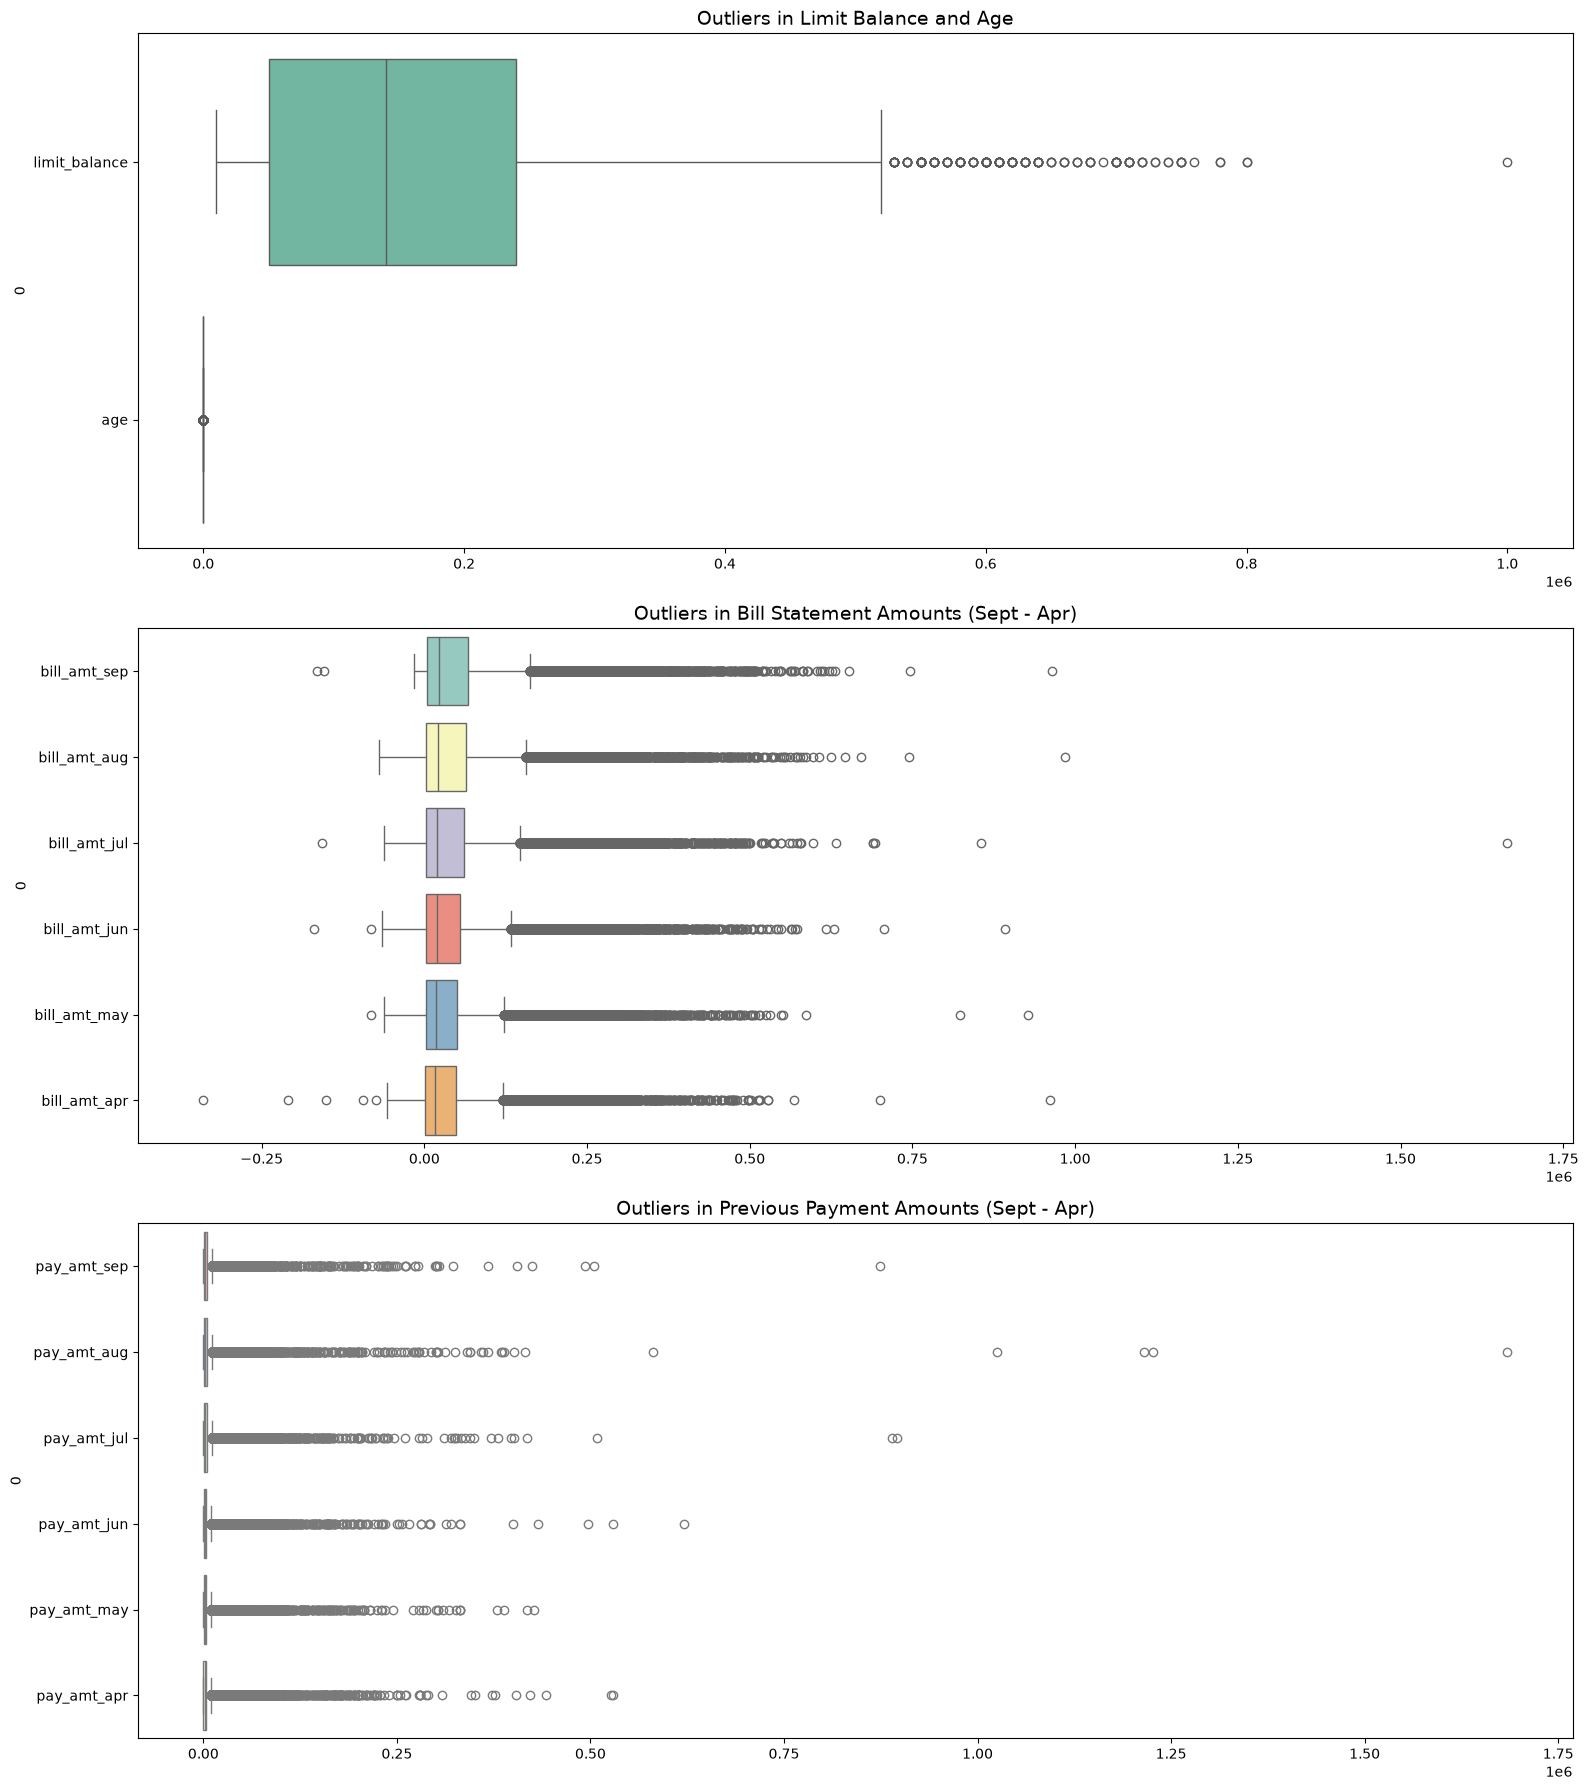

In [20]:
# Identify continuous numerical columns to check for outliers
bill_cols = [col for col in df_copy.columns if 'bill_amt' in col]
pay_cols = [col for col in df_copy.columns if 'pay_amt' in col]
numeric_cols = ['limit_balance', 'age']

# Create subplots to inspect outliers
fig, axes = plt.subplots(3, 1, figsize=(16, 18))

# Plot 1: Limit Balance and Age
sns.boxplot(data=df_copy[numeric_cols], ax=axes[0], orient='h', palette='Set2')
axes[0].set_title('Outliers in Limit Balance and Age', fontsize=14)

# Plot 2: Bill Statement Amounts
sns.boxplot(data=df_copy[bill_cols], ax=axes[1], orient='h', palette='Set3')
axes[1].set_title('Outliers in Bill Statement Amounts (Sept - Apr)', fontsize=14)

# Plot 3: Previous Payment Amounts
sns.boxplot(data=df_copy[pay_cols], ax=axes[2], orient='h', palette='Pastel1')
axes[2].set_title('Outliers in Previous Payment Amounts (Sept - Apr)', fontsize=14)

plt.tight_layout()
plt.show()

In [21]:
# Calculate the number of outliers using the IQR (Interquartile Range) method for these numeric fields
print("Number of outliers per continuous feature using IQR method:")
for col in numeric_cols + bill_cols + pay_cols:
    Q1 = df_copy[col].quantile(0.25)
    Q3 = df_copy[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df_copy[(df_copy[col] < lower_bound) | (df_copy[col] > upper_bound)]
    print(f"{col:25} : {len(outliers)} outliers (out of {len(df_copy)} records)")

Number of outliers per continuous feature using IQR method:
limit_balance             : 167 outliers (out of 30000 records)
age                       : 272 outliers (out of 30000 records)
bill_amt_sep              : 2400 outliers (out of 30000 records)
bill_amt_aug              : 2395 outliers (out of 30000 records)
bill_amt_jul              : 2469 outliers (out of 30000 records)
bill_amt_jun              : 2622 outliers (out of 30000 records)
bill_amt_may              : 2725 outliers (out of 30000 records)
bill_amt_apr              : 2693 outliers (out of 30000 records)
pay_amt_sep               : 2745 outliers (out of 30000 records)
pay_amt_aug               : 2714 outliers (out of 30000 records)
pay_amt_jul               : 2598 outliers (out of 30000 records)
pay_amt_jun               : 2994 outliers (out of 30000 records)
pay_amt_may               : 2945 outliers (out of 30000 records)
pay_amt_apr               : 2958 outliers (out of 30000 records)


### Pairplot Analysis

We will visualize the relationships and individual distributions of a key subset of continuous variables (limit_balance, age, bill_amt_sep, and pay_amt_sep). The diagonal of this plot displays the distribution shape of each variable, color-coded by default status.

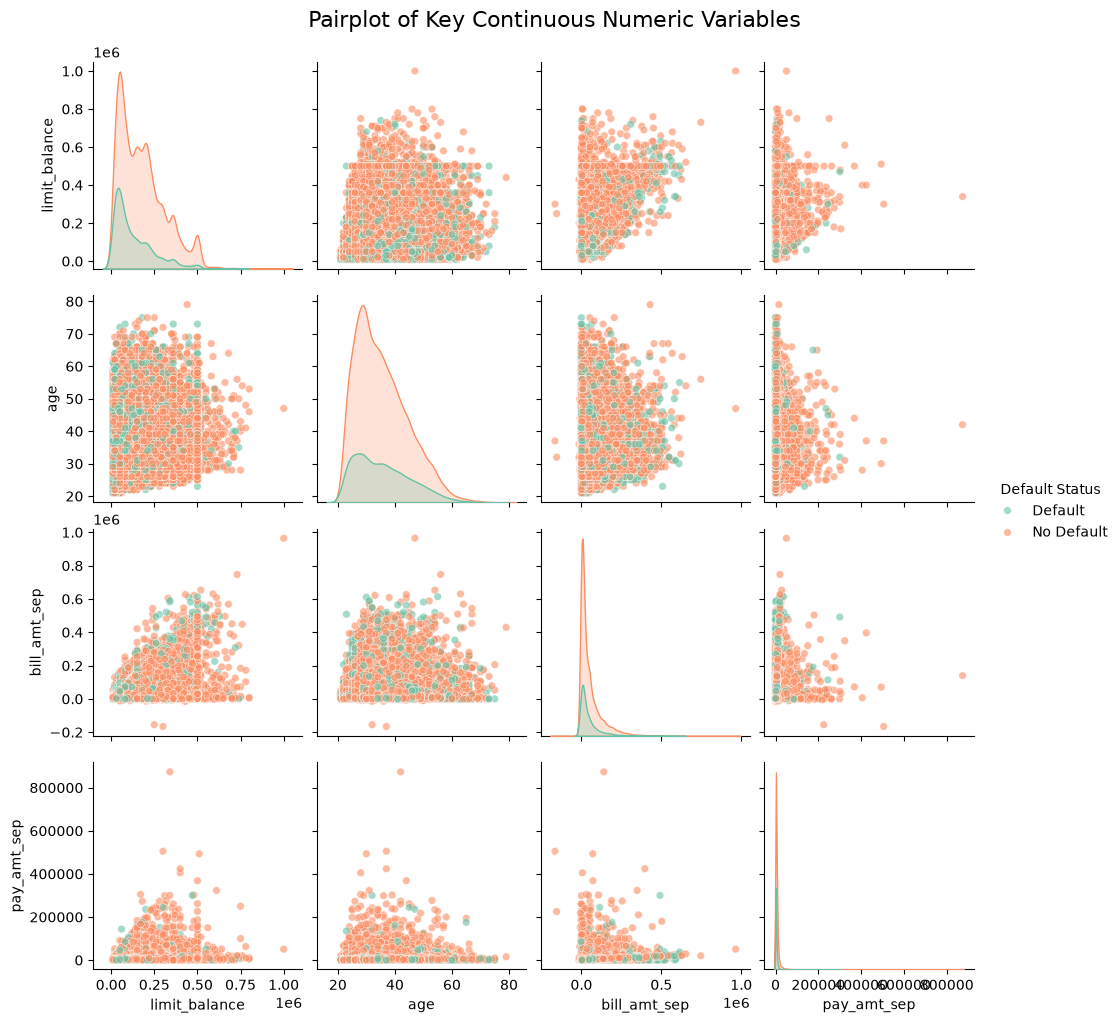

In [22]:
# Select representative continuous variables and the target variable for comparison
selected_cols = ['limit_balance', 'age', 'bill_amt_sep', 'pay_amt_sep', 'default_payment_next_month']

# Map target variable dynamically to text labels for the legend
pairplot_df = df_copy[selected_cols].copy()
pairplot_df['Default Status'] = pairplot_df['default_payment_next_month'].map({0: 'No Default', 1: 'Default'})

# Create the pairplot with KDE on the diagonal
g = sns.pairplot(
    pairplot_df.drop(columns=['default_payment_next_month']),
    hue='Default Status',
    diag_kind='kde',
    palette='Set2',
    plot_kws={'alpha': 0.6, 's': 30}
)

g.fig.suptitle('Pairplot of Key Continuous Numeric Variables', y=1.02, fontsize=16)
plt.show()

## Repayment Status Distribution Comparison

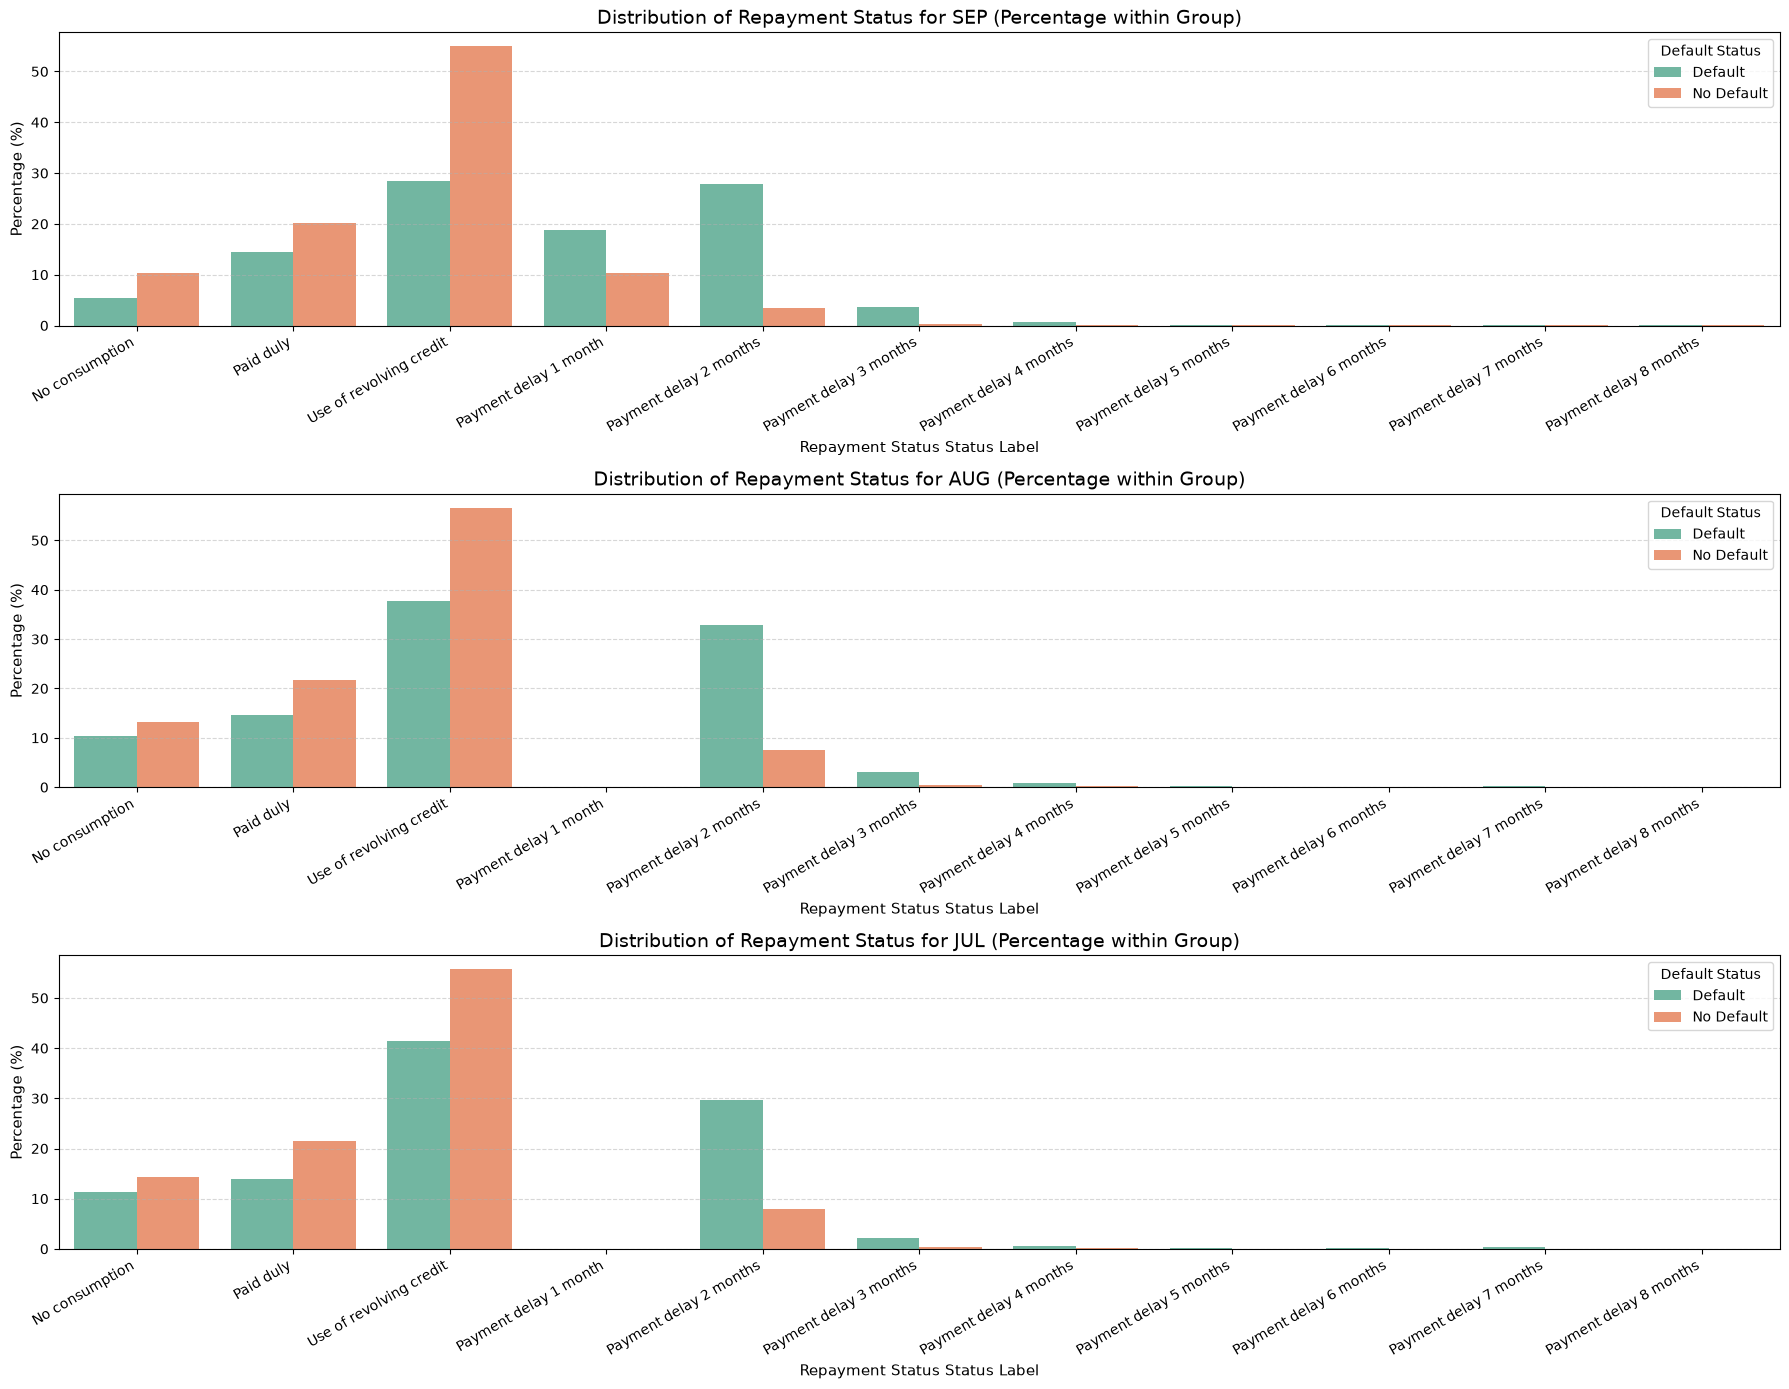

In [23]:
# Get repayment status columns
pay_status_cols = [
    'repayment_status_sep', 'repayment_status_aug', 'repayment_status_jul',
    'repayment_status_jun', 'repayment_status_may', 'repayment_status_apr'
]

# Create a long-form DataFrame for easier multi-plot visualization with seaborn
df_melted = pd.melt(
    df_copy,
    id_vars=['default_payment_next_month'],
    value_vars=pay_status_cols,
    var_name='Month',
    value_name='Status'
)

# Map target and status numerical categories to descriptive labels dynamically
df_melted['Default Status'] = df_melted['default_payment_next_month'].map(default_labels)
df_melted['Repayment Status'] = df_melted['Status'].map(repayment_status_labels)

# Focus on the most recent 3 months for highly readable visualization (September, August, July)
months_to_plot = ['repayment_status_sep', 'repayment_status_aug', 'repayment_status_jul']

plt.figure(figsize=(18, 14))

for i, col in enumerate(months_to_plot, 1):
    plt.subplot(3, 1, i)

    # Calculate percentage within each default category to adjust for class imbalance
    temp_df = df_copy[[col, 'default_payment_next_month']].copy()
    temp_df['Default Status'] = temp_df['default_payment_next_month'].map(default_labels)
    temp_df['Repayment Status'] = temp_df[col].map(repayment_status_labels)

    # Group and calculate relative percentages
    grouped_data = (
        temp_df.groupby(['Default Status', 'Repayment Status'])
        .size()
        .groupby(level=0, group_keys=False)
        .apply(lambda x: 100 * x / float(x.sum()))
        .reset_index(name='Percentage')
    )

    # Sort by the numeric values of status for orderly layout
    status_order = [repayment_status_labels[k] for k in sorted(repayment_status_labels.keys()) if repayment_status_labels[k] in grouped_data['Repayment Status'].values]

    sns.barplot(
        data=grouped_data,
        x='Repayment Status',
        y='Percentage',
        hue='Default Status',
        order=status_order,
        palette='Set2'
    )

    plt.title(f"Distribution of Repayment Status for {col.replace('repayment_status_', '').upper()} (Percentage within Group)", fontsize=14)
    plt.xlabel('Repayment Status Status Label', fontsize=11)
    plt.ylabel('Percentage (%)', fontsize=11)
    plt.xticks(rotation=30, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.legend(title='Default Status')

plt.tight_layout()
plt.show()

### Correlation Heatmap

We will construct a correlation matrix of our numerical features to visualize how they associate with one another, as well as their direct linear correlations with the target variable default_payment_next_month.

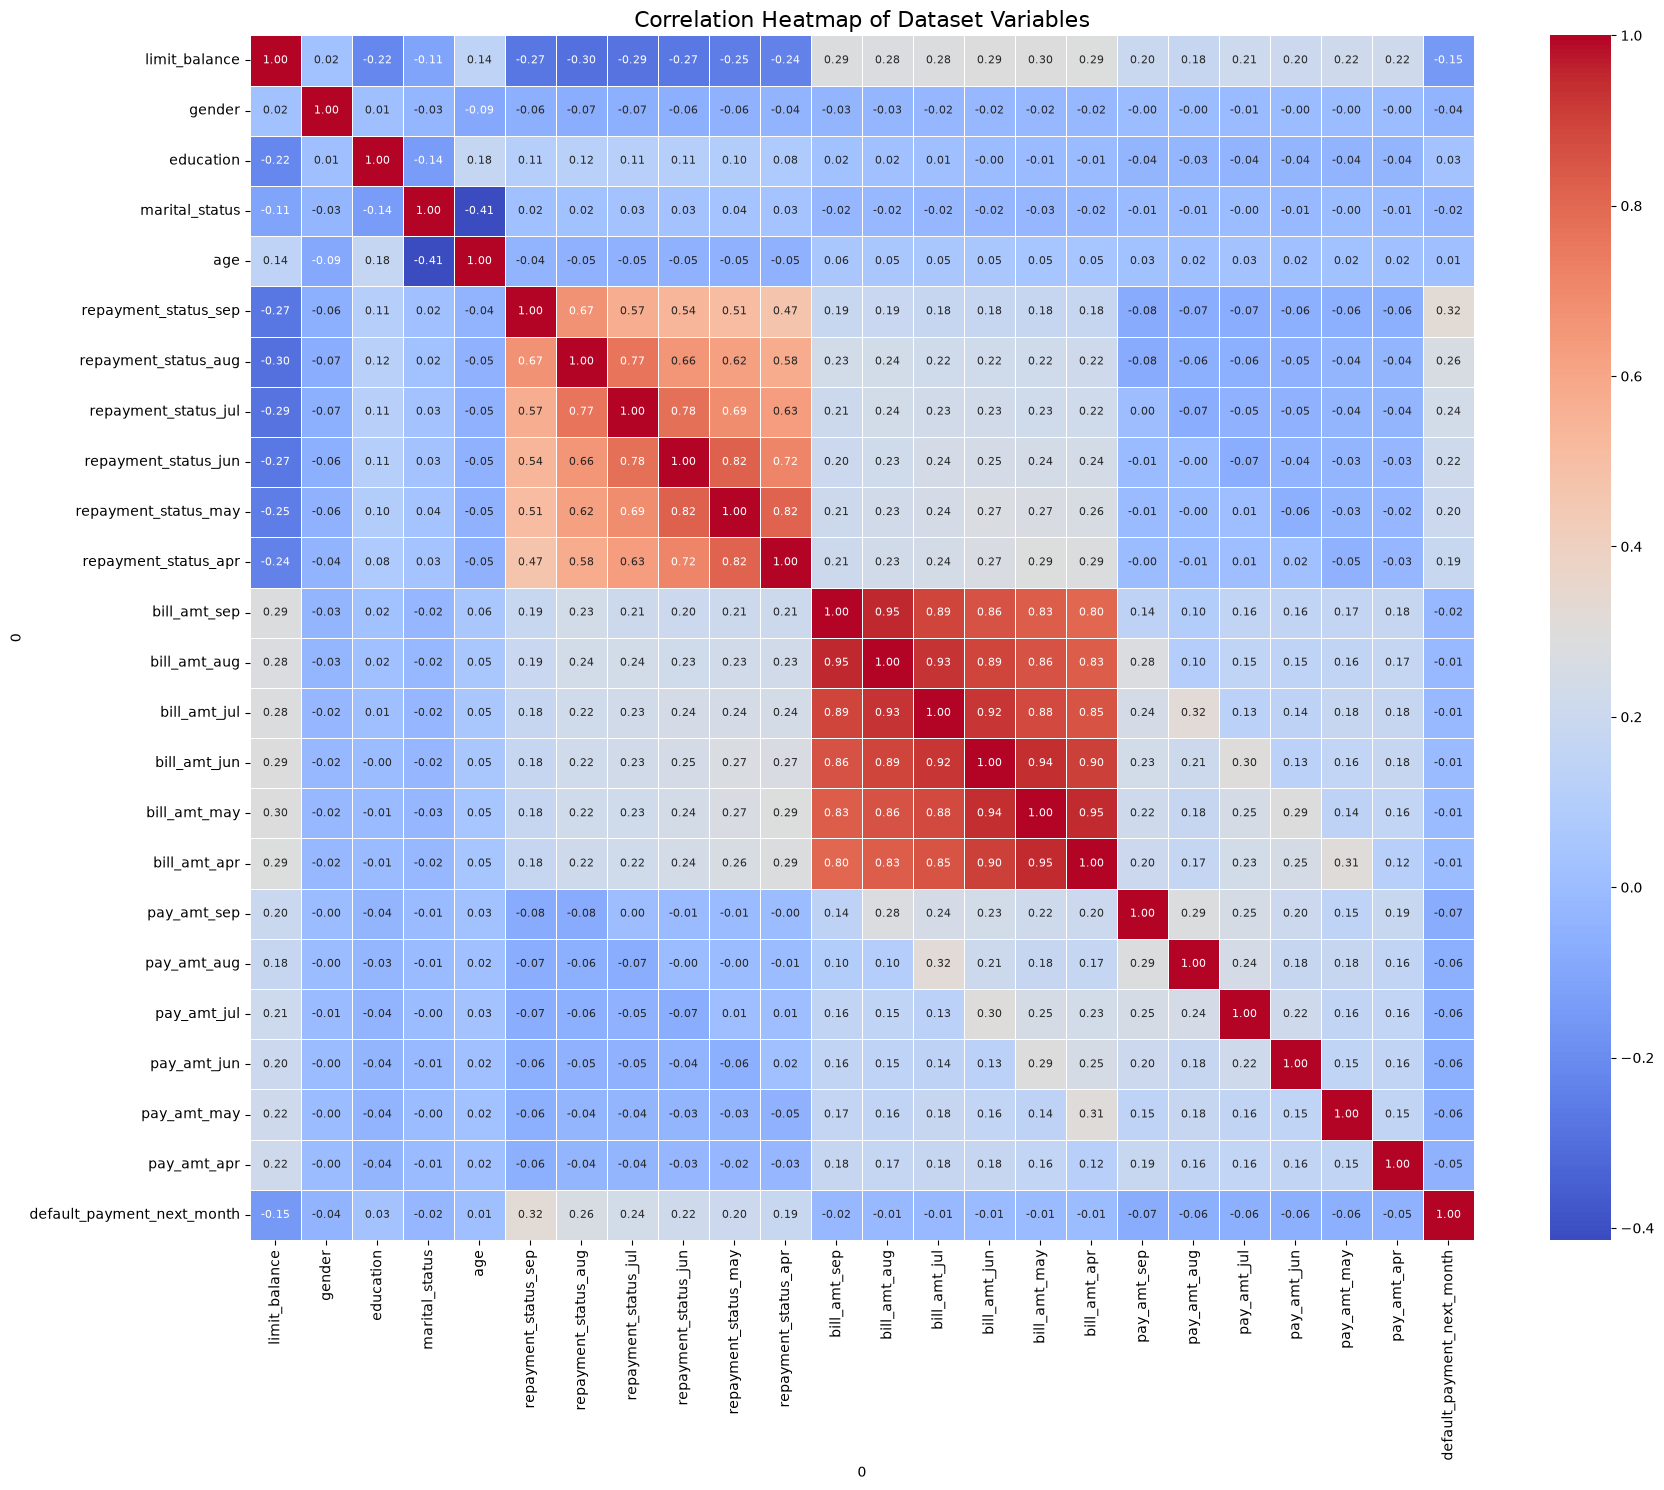

In [24]:
# Calculate correlation matrix for numerical columns
corr_matrix = df_copy.corr()

# Plot the correlation heatmap
plt.figure(figsize=(18, 15))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar=True,
    annot_kws={'size': 8}
)

plt.title('Correlation Heatmap of Dataset Variables', fontsize=16)
plt.tight_layout()
plt.show()

### Box Plot

To inspect the detailed distribution spread, skewness, and extreme values, we will construct box plots grouped by feature categories.

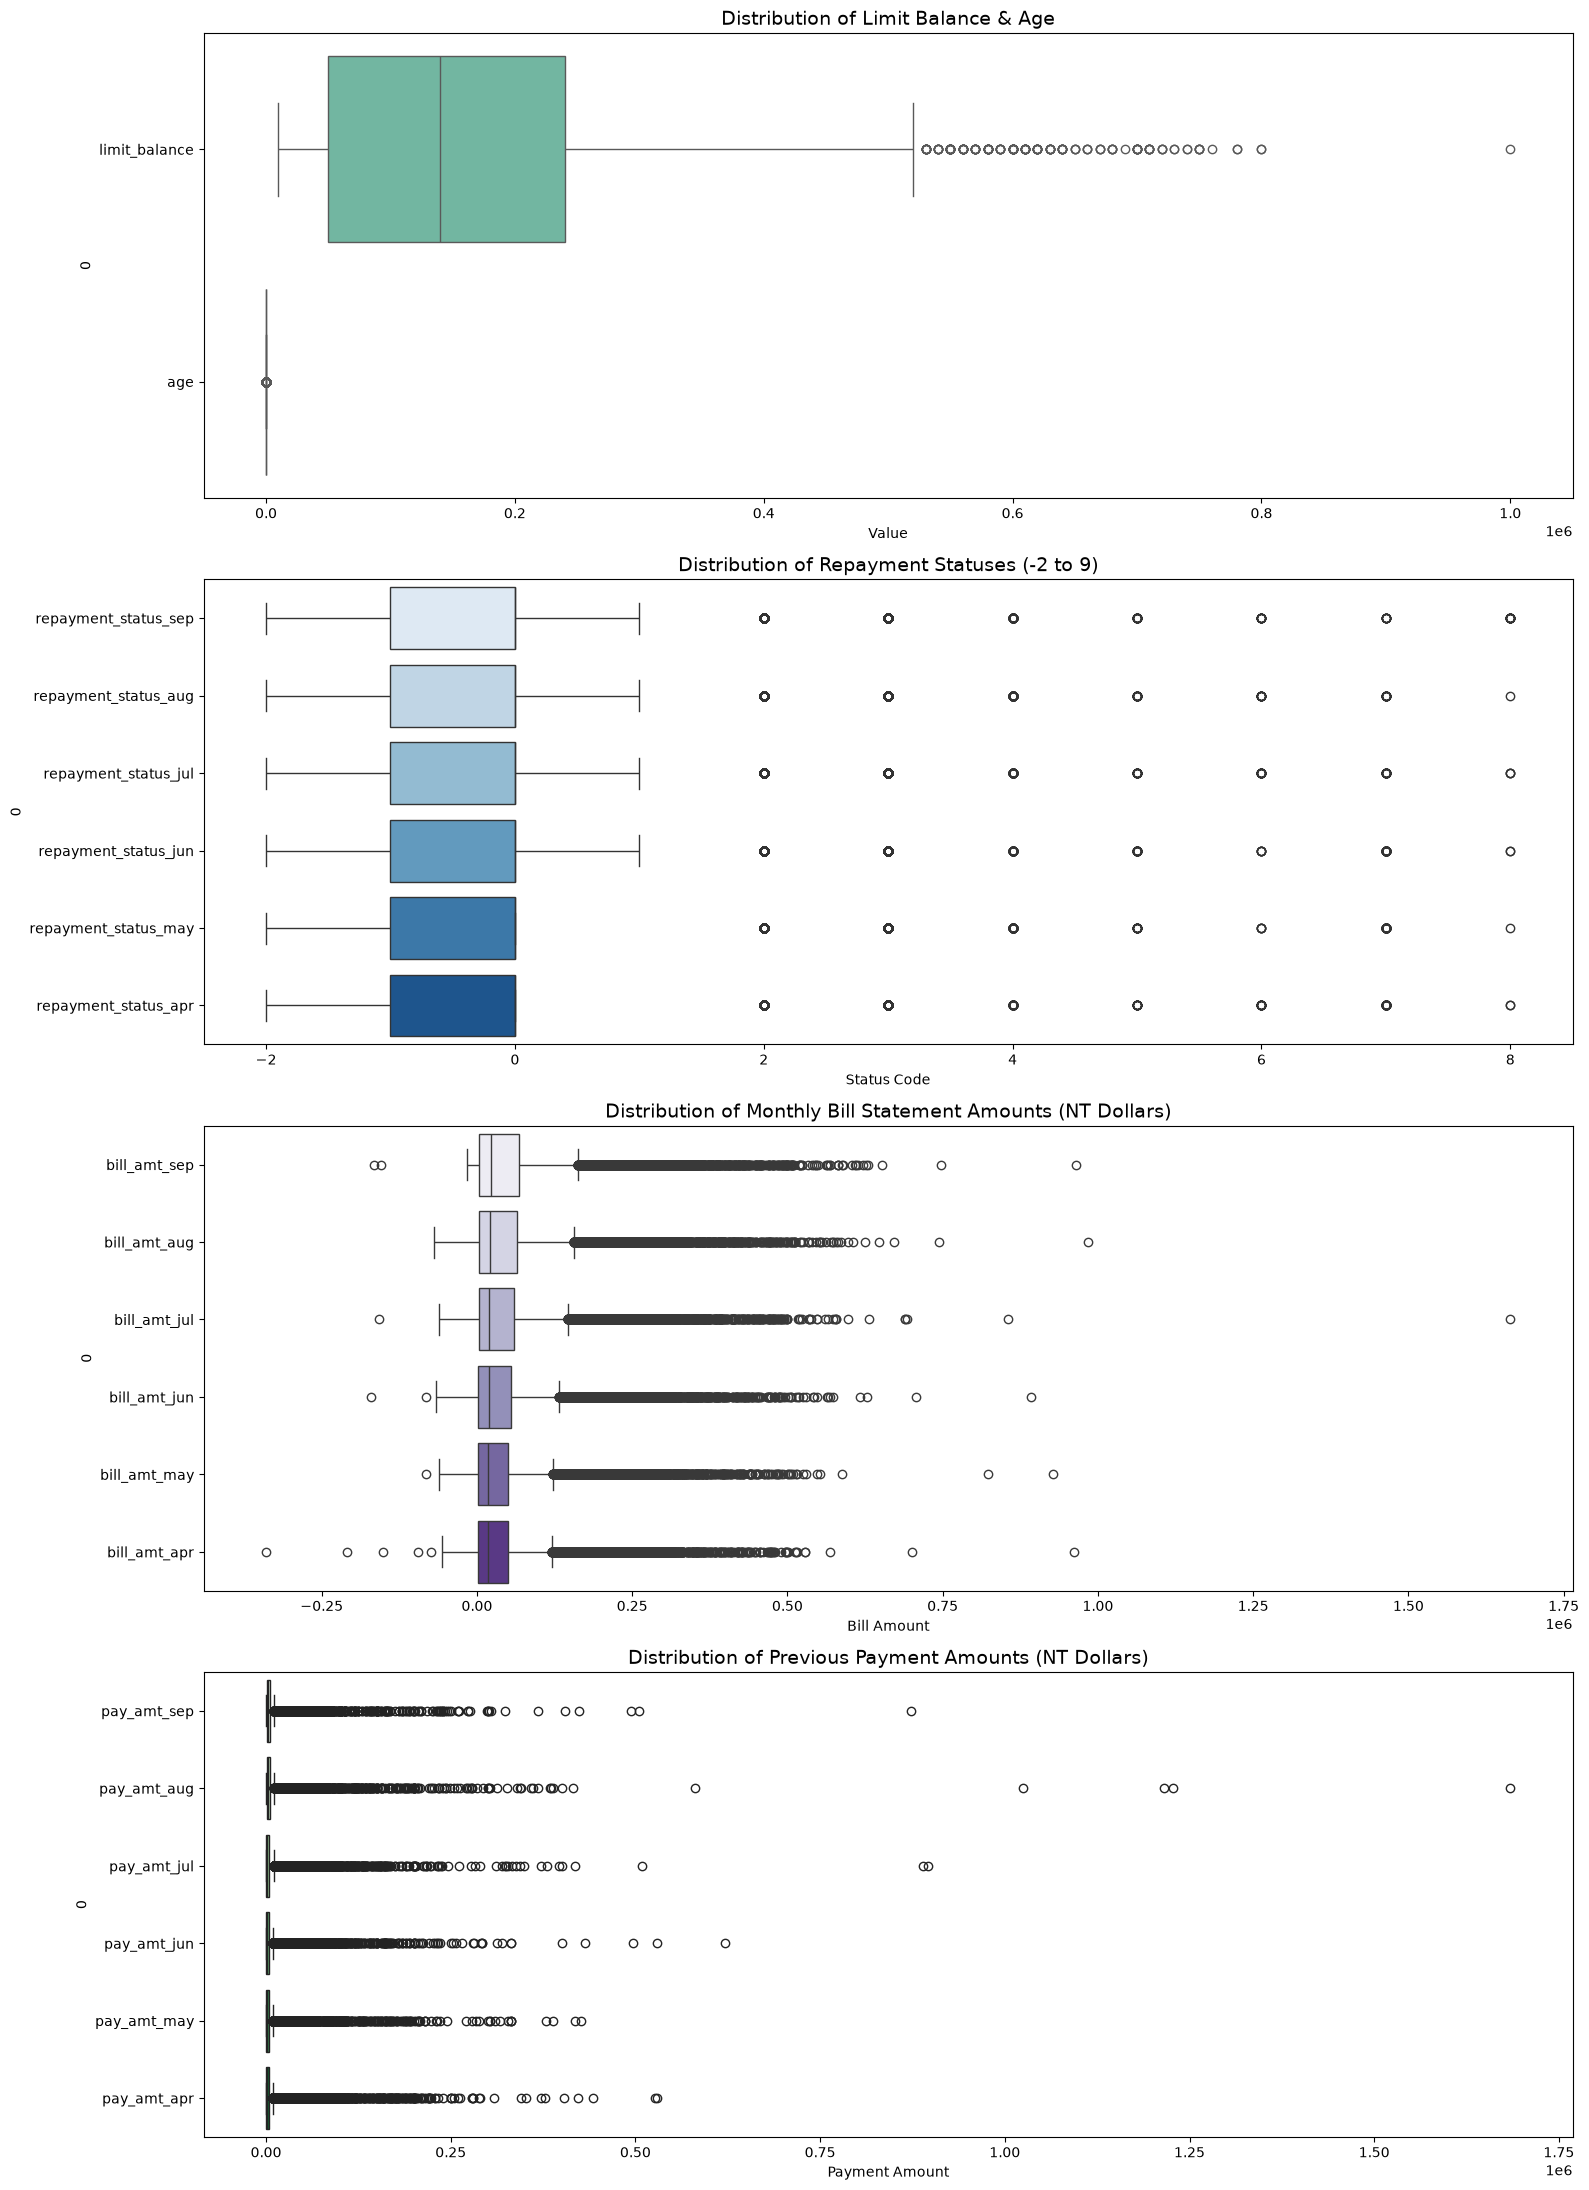

In [25]:
# Configure a multi-panel subplot layout
fig, axes = plt.subplots(4, 1, figsize=(16, 22))

# Panel 1: Demographic continuous and discrete features (excluding category mappings)
sns.boxplot(data=df_copy[['limit_balance', 'age']], orient='h', palette='Set2', ax=axes[0])
axes[0].set_title('Distribution of Limit Balance & Age', fontsize=14)
axes[0].set_xlabel('Value')

# Panel 2: Repayment Statuses (September - April)
repay_cols = ['repayment_status_sep', 'repayment_status_aug', 'repayment_status_jul',
              'repayment_status_jun', 'repayment_status_may', 'repayment_status_apr']
sns.boxplot(data=df_copy[repay_cols], orient='h', palette='Blues', ax=axes[1])
axes[1].set_title('Distribution of Repayment Statuses (-2 to 9)', fontsize=14)
axes[1].set_xlabel('Status Code')

# Panel 3: Monthly Bill Statement Amounts
bill_cols = ['bill_amt_sep', 'bill_amt_aug', 'bill_amt_jul', 'bill_amt_jun', 'bill_amt_may', 'bill_amt_apr']
sns.boxplot(data=df_copy[bill_cols], orient='h', palette='Purples', ax=axes[2])
axes[2].set_title('Distribution of Monthly Bill Statement Amounts (NT Dollars)', fontsize=14)
axes[2].set_xlabel('Bill Amount')

# Panel 4: Monthly Previous Payment Amounts
pay_cols = ['pay_amt_sep', 'pay_amt_aug', 'pay_amt_jul', 'pay_amt_jun', 'pay_amt_may', 'pay_amt_apr']
sns.boxplot(data=df_copy[pay_cols], orient='h', palette='Greens', ax=axes[3])
axes[3].set_title('Distribution of Previous Payment Amounts (NT Dollars)', fontsize=14)
axes[3].set_xlabel('Payment Amount')

plt.tight_layout()
plt.show()

## Target Distribution

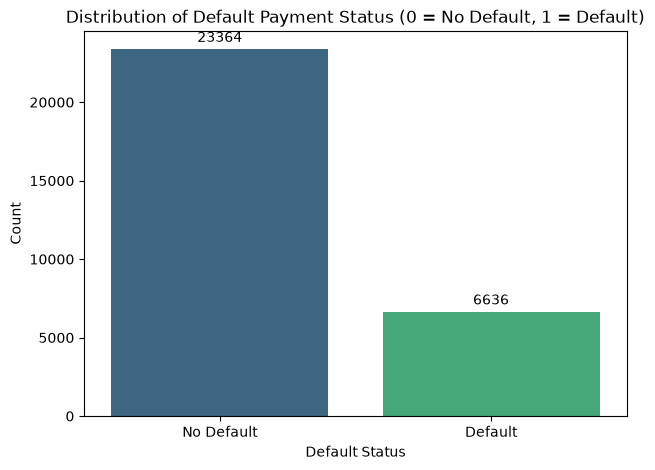

In [26]:
plt.figure(figsize=(7, 5))
sns.countplot(x='default_payment_next_month', hue='default_payment_next_month', data=df_copy, palette='viridis', legend=False)
plt.title('Distribution of Default Payment Status (0 = No Default, 1 = Default)')
plt.xlabel('Default Status')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['No Default', 'Default'])

# Annotate bars with counts
ax = plt.gca()
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points')

plt.show()

In [27]:
# Define features (x) and target variable (y)
X = df_copy.drop('default_payment_next_month', axis=1) # Drop the target variable from the DataFrame so we'll be left with features
y = df_copy['default_payment_next_month'] # Target

# Let's see the features
print("~" * 20)
print(" Features (X):")
print("~" * 20)
print(X.head())

# Shape of featrues
print("\nShape of X:", X.shape)
print()

# Let's see the target/label
print("~" * 20)
print("Target (y):")
print("~" * 20)
print(y.head())

# shape of target
print("\nShape of y:", y.shape)

# See unique values
print("\nUnique species:", y.unique())


~~~~~~~~~~~~~~~~~~~~
 Features (X):
~~~~~~~~~~~~~~~~~~~~
0  limit_balance  gender  education  marital_status  age  \
0          20000       2          2               1   24   
1         120000       2          2               2   26   
2          90000       2          2               2   34   
3          50000       2          2               1   37   
4          50000       1          2               1   57   

0  repayment_status_sep  repayment_status_aug  repayment_status_jul  \
0                     2                     2                    -1   
1                    -1                     2                     0   
2                     0                     0                     0   
3                     0                     0                     0   
4                    -1                     0                    -1   

0  repayment_status_jun  repayment_status_may  ...  bill_amt_jul  \
0                    -1                    -2  ...           689   
1                  

## Split Dataset

In [28]:
# Split the data: 80% training, 20% testing
# stratify=y ensures each split has the same proportion of each species
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=234, stratify=y
)

# Check the splits
print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)
print()

print("~" * 38)
print(" Training set species distribution:")
print("~" * 38)
print(y_train.value_counts())
print()

print("~" * 38)
print(" Testing set species distribution:")
print("~" * 38)
print(y_test.value_counts())

Training set size: (24000, 23)
Testing set size: (6000, 23)

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Training set species distribution:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
default_payment_next_month
0    18691
1     5309
Name: count, dtype: int64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 Testing set species distribution:
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
default_payment_next_month
0    4673
1    1327
Name: count, dtype: int64


## Feature Scaling

In [29]:
# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform both training and testing data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Check the scaling
print("~" * 40)
print("Original training data (first 5 rows):")
print("~" * 40)
print(X_train.head())
print()

print("~" * 40)
print("Scaled training data (first 5 rows):")
print("~" * 40)
print(pd.DataFrame(X_train_scaled, columns=X_train.columns).head())
print()

print("~" * 45)
print("Mean of scaled features (should be close to 0):")
print("~" * 45)
print(pd.DataFrame(X_train_scaled, columns=X_train.columns).mean())
print()

print("~" * 45)
print("Std of scaled features (should be close to 1):")
print("~" * 45)
print(pd.DataFrame(X_train_scaled, columns=X_train.columns).std())

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Original training data (first 5 rows):
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
0      limit_balance  gender  education  marital_status  age  \
3483           50000       1          1               1   29   
7278          150000       1          1               1   50   
16595         430000       1          2               2   30   
18724          20000       2          2               1   28   
12096          50000       1          3               3   55   

0      repayment_status_sep  repayment_status_aug  repayment_status_jul  \
3483                      0                     0                     0   
7278                      0                     0                     0   
16595                    -1                    -1                     2   
18724                    -1                    -1                     0   
12096                     2                     0                     0   

0      repayment_status_jun  repayment_stat

## Model Training

In [30]:
# --- Perform Random Under-sampling on the Training Data ---
X_train_df = pd.DataFrame(X_train, columns=X_train.columns)
y_train_series = pd.Series(y_train, name='target')
train_temp = pd.concat([X_train_df, y_train_series], axis=1)

default_indices = train_temp[train_temp['target'] == 1].index
no_default_indices = train_temp[train_temp['target'] == 0].index

# Randomly sample 'no default' indices to match the number of 'default' indices
np.random.seed(234)
under_sampled_no_default_indices = np.random.choice(
    no_default_indices, size=len(default_indices), replace=False
)

# Combine and shuffle the balanced dataset
balanced_indices = np.concatenate([default_indices, under_sampled_no_default_indices])
balanced_train = train_temp.loc[balanced_indices].sample(frac=1, random_state=234)

# Extract balanced features and target
X_train_balanced = balanced_train.drop(columns=['target'])
y_train_balanced = balanced_train['target']

print(f"Original training size: {X_train.shape[0]} ({y_train.value_counts().to_dict()})")
print(f"Balanced training size (Under-sampled): {X_train_balanced.shape[0]} ({y_train_balanced.value_counts().to_dict()})\n")

# --- Train Random Forest Classifier with Tuned Hyperparameters ---
# We refine depth, tree count, and leaf rules to improve model F1 performance
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=234,
    n_jobs=-1
)

print("Training refined model on under-sampled dataset...")
rf_model.fit(X_train_balanced, y_train_balanced)

# Explicitly display the trained model configuration representation
display(rf_model)

# Predict on the test set
rf_pred = rf_model.predict(X_test)
print("Done! Re-run the evaluation cell below to check the updated F1-score performance.")

Original training size: 24000 ({0: 18691, 1: 5309})
Balanced training size (Under-sampled): 10618 ({1: 5309, 0: 5309})

Training refined model on under-sampled dataset...


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",234
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

Done! Re-run the evaluation cell below to check the updated F1-score performance.


### Model Training & Evaluation Flow

We train our Random Forest model on the physically balanced dataset (Random Under-sampling) and evaluate the predictions against actual test values.

In [31]:
# Create a comparison DataFrame
comparison_df = pd.DataFrame({
    'Actual_Value': y_test.values,
    'Predicted_Value': rf_pred
})

# Add a column indicating if the prediction was correct
comparison_df['Correct_Prediction'] = comparison_df['Actual_Value'] == comparison_df['Predicted_Value']

# Map the 0 and 1 values to descriptive labels for easier readability
comparison_df['Actual_Label'] = comparison_df['Actual_Value'].map({0: 'No Default', 1: 'Default'})
comparison_df['Predicted_Label'] = comparison_df['Predicted_Value'].map({0: 'No Default', 1: 'Default'})

# Display a sample of correct and incorrect predictions
print("--- Sample of 10 Random Predictions ---")
display(comparison_df[['Actual_Label', 'Predicted_Label', 'Correct_Prediction']].sample(10, random_state=42))

# Display the overall count of correct vs incorrect predictions in the test set
print("\n--- Overall Prediction Summary on Test Set ---")
display(comparison_df['Correct_Prediction'].value_counts().rename({True: 'Correct', False: 'Incorrect'}))

--- Sample of 10 Random Predictions ---


,Actual_Label,Predicted_Label,Correct_Prediction
1782,No Default,No Default,True
3917,No Default,No Default,True
221,Default,Default,True
2135,Default,Default,True
5224,No Default,No Default,True
1168,No Default,No Default,True
879,No Default,Default,False
156,No Default,Default,False
1657,Default,Default,True
323,No Default,No Default,True



--- Overall Prediction Summary on Test Set ---


Correct_Prediction
Correct      4589
Incorrect    1411
Name: count, dtype: int64

## Performance Metrics & Confusion Matrix


Random Forest Test Accuracy: 76.48%
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  No Default       0.88      0.80      0.84      4673
     Default       0.48      0.63      0.54      1327

    accuracy                           0.76      6000
   macro avg       0.68      0.72      0.69      6000
weighted avg       0.79      0.76      0.78      6000



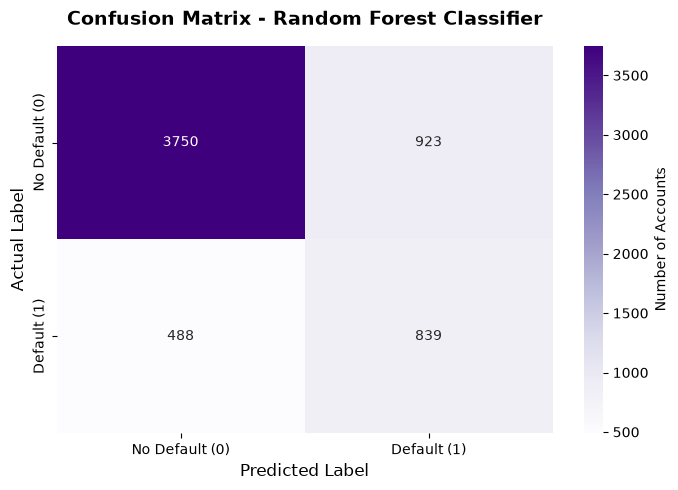

In [32]:
# Evaluate performance
rf_accuracy = accuracy_score(y_test, rf_pred)
print("\n" + "=" * 60)
print(f"Random Forest Test Accuracy: {rf_accuracy*100:.2f}%")
print("=" * 60)
print("CLASSIFICATION REPORT:")
print(classification_report(y_test, rf_pred, target_names=['No Default', 'Default']))
print("=" * 60)

# Create a styled confusion matrix heatmap
cm_rf = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['No Default (0)', 'Default (1)'],
    yticklabels=['No Default (0)', 'Default (1)'],
    cbar_kws={'label': 'Number of Accounts'}
)
plt.title('Confusion Matrix - Random Forest Classifier', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Actual Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

### Feature Importance Analysis

Understanding which features have the strongest predictive influence on the model's decisions.

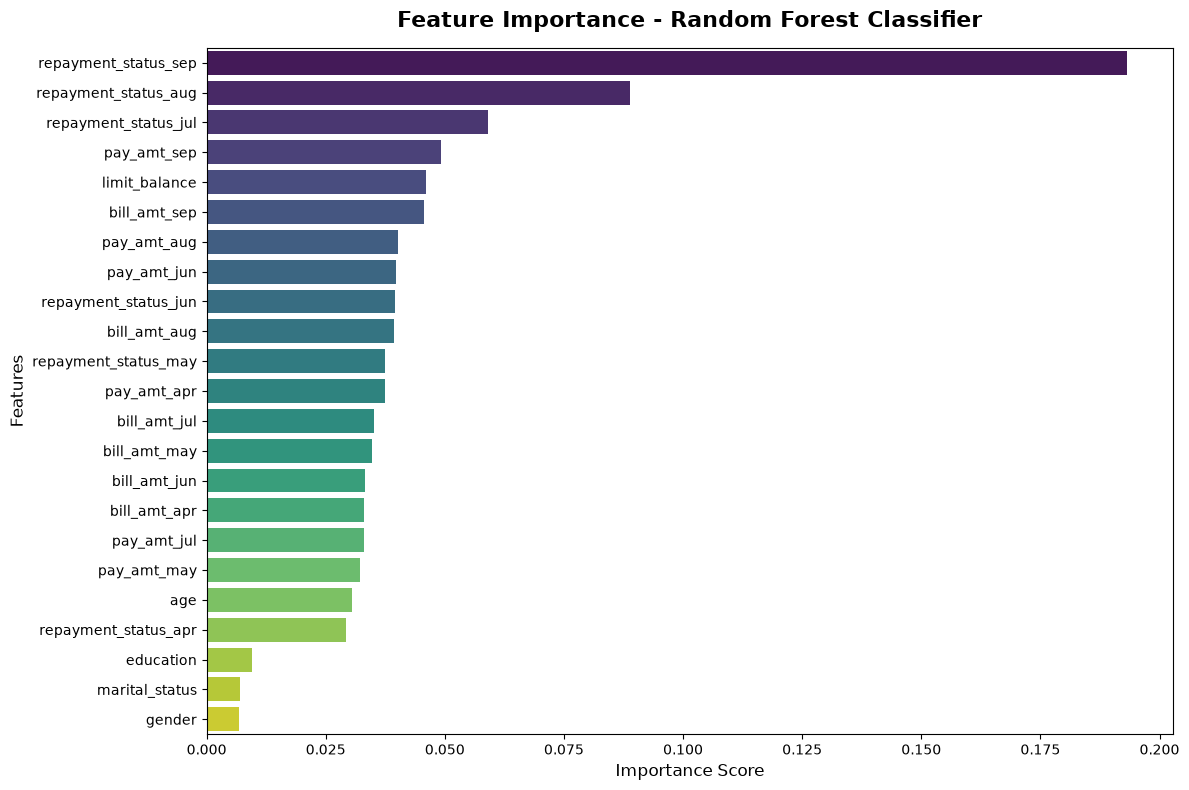

Top 10 Most Important Features:


,Feature,Importance
5,repayment_status_sep,0.193136
6,repayment_status_aug,0.088879
7,repayment_status_jul,0.058967
17,pay_amt_sep,0.049139
0,limit_balance,0.046131
11,bill_amt_sep,0.045590
18,pay_amt_aug,0.040088
20,pay_amt_jun,0.039795
8,repayment_status_jun,0.039540
12,bill_amt_aug,0.039324


In [33]:
# Extract feature importances
importances = rf_model.feature_importances_
feature_names = X_train.columns

# Create a DataFrame for importances
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot the feature importances (updated to resolve the Seaborn FutureWarning)
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, hue='Feature', palette='viridis', legend=False)
plt.title('Feature Importance - Random Forest Classifier', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

# Display the top 10 features
print("Top 10 Most Important Features:")
display(feature_imp_df.head(10))

## Save Model

In [34]:
# Save the model - corrected variable name from 'model' to 'rf_model'
model_filename = 'best_default_dectector_model.pkl'
joblib.dump(rf_model, model_filename)
print(f"Model successfully saved as '{model_filename}'")

# Also save the scaler (important for making predictions later)
scaler_filename = 'default_dectector_model.pkl'
joblib.dump(scaler, scaler_filename)
print(f"Scaler successfully saved as '{scaler_filename}'")

Model successfully saved as 'best_default_dectector_model.pkl'
Scaler successfully saved as 'default_dectector_model.pkl'


In [35]:
# Test loading the model and scaler back
loaded_model = joblib.load(model_filename)
loaded_scaler = joblib.load(scaler_filename)
print("Model and scaler loaded successfully!")

# Verify it works by making a test prediction on the first 5 test samples
test_prediction = loaded_model.predict(X_test[:5])
print("\nTest predictions with loaded model:")
print(test_prediction)
print("\nActual values:")
print(y_test[:5].values)

Model and scaler loaded successfully!

Test predictions with loaded model:
[1 0 0 0 0]

Actual values:
[1 0 0 0 0]


## To load model

In [37]:
"""
import joblib

scaler = joblib.load("default_dectector_model.pkl")

model = joblib.load("best_default_dectector_model.pkl")

scaled_data = scaler.transform(new_data)

predictions = model.predict(scaled_data)
"""

'\nimport joblib\n\nscaler = joblib.load("default_dectector_model.pkl")\n\nmodel = joblib.load("best_default_dectector_model.pkl")\n\nscaled_data = scaler.transform(new_data)\n\npredictions = model.predict(scaled_data)\n'